In [135]:
import json
import cv2
import os
import matplotlib.pyplot as plt
import sys
import numpy as np
import math
from scipy.optimize import linear_sum_assignment

sys.path.append(os.path.join("..", "src"))
from detector import detect_dots

In [136]:
meta_path = os.path.join("..", "data", "sample_annotations.json")
images_dir = os.path.join("..", "data", "sample_images")

with open(meta_path, "r", encoding="utf-8") as f:
    dev_data = json.load(f)

dev_ids = dev_data["dev_ids"]

dev_images = {
    idx: cv2.imread(os.path.join(images_dir, f"{idx}.png")) for idx in dev_ids
}

dev_pixels = {
    idx: [{"x": cx, "y": cy} for cx, cy in detect_dots(dev_images[idx])]
    for idx in dev_ids
}

In [137]:
print(dev_pixels)

{4434: [{'x': 106, 'y': 69}, {'x': 284, 'y': 34}, {'x': 462, 'y': 62}, {'x': 639, 'y': 51}, {'x': 817, 'y': 83}, {'x': 995, 'y': 37}], 4435: [{'x': 109, 'y': 65}, {'x': 468, 'y': 54}, {'x': 827, 'y': 44}, {'x': 1186, 'y': 34}], 4438: [{'x': 130, 'y': 176}, {'x': 289, 'y': 150}, {'x': 448, 'y': 122}, {'x': 608, 'y': 92}, {'x': 767, 'y': 74}, {'x': 926, 'y': 56}, {'x': 1086, 'y': 37}], 4439: [{'x': 106, 'y': 164}, {'x': 284, 'y': 167}, {'x': 462, 'y': 149}, {'x': 640, 'y': 86}, {'x': 818, 'y': 50}, {'x': 996, 'y': 36}], 4441: [{'x': 94, 'y': 195}, {'x': 322, 'y': 161}, {'x': 550, 'y': 72}, {'x': 779, 'y': 38}, {'x': 1007, 'y': 96}], 4442: [{'x': 95, 'y': 69}, {'x': 452, 'y': 34}, {'x': 810, 'y': 35}, {'x': 1167, 'y': 60}], 4445: [{'x': 111, 'y': 60}, {'x': 389, 'y': 64}, {'x': 668, 'y': 58}, {'x': 946, 'y': 36}, {'x': 1225, 'y': 34}], 4489: [{'x': 95, 'y': 119}, {'x': 331, 'y': 59}, {'x': 567, 'y': 35}, {'x': 803, 'y': 59}, {'x': 1038, 'y': 69}], 4540: [{'x': 120, 'y': 36}, {'x': 325, 'y

do poradzenia sobie z przeliczeniem polozenia punktow w pikselach na wartosci na osiach, będziemy się korzystać z interpolacji liniowej, zdefiniowanej na podstawie dwoch znanych punktow referencyjnych dla kazdej z osi

musimy sobie troche przeanalizować plik sample_annotations.json

In [138]:
print(dev_data.keys())
print(type(dev_data['samples']))
print(len(dev_data['samples']))
print(dev_data['samples'][0])

dict_keys(['dataset_name', 'original_split', 'selection_criteria', 'dev_ids', 'test_ids', 'samples'])
<class 'list'>
30
{'models': [{'name': 'Air transport', 'color': '#DAA520', 'label': 'Air transport', 'bboxes': [{'y': 63, 'x': 100, 'w': 13, 'h': 13}, {'y': 26, 'x': 278, 'w': 13, 'h': 13}, {'y': 56, 'x': 456, 'w': 13, 'h': 13}, {'y': 45, 'x': 633, 'w': 13, 'h': 13}, {'y': 77, 'x': 811, 'w': 13, 'h': 13}, {'y': 31, 'x': 989, 'w': 13, 'h': 13}], 'y': [5700.0, 6100.0, 5772.0, 5891.0, 5545.0, 6047.0], 'x': [0, 1, 2, 3, 4, 5]}], 'type': 'dot_line', 'general_figure_info': {'title': {'text': 'Number of domestic takeoffs and takeoffs abroad of air carriers registered in Belarus', 'bbox': {'y': 9, 'x': 62.07375000000002, 'w': 765.0, 'h': 18}}, 'x_axis': {'minor_ticks': {'values': [], 'bboxes': []}, 'major_labels': {'values': ['1998', '1999', '2000', '2001', '2002', '2003', '1998', '1999', '2000', '2001', '2002', '2003'], 'bboxes': [{'y': 598, 'x': 100, 'w': 14, 'h': 24.4375}, {'y': 598, 'x': 

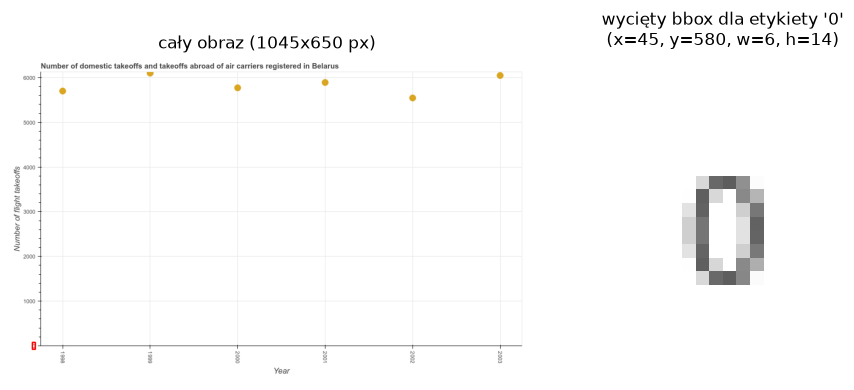

In [139]:
sample_id = dev_ids[0]
img = dev_images[sample_id]
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
sample_id = dev_ids[0]

sample_annot = next(
    sample for sample in dev_data["samples"]
    if sample["image_index"] == sample_id
)

fig_info = sample_annot["general_figure_info"]
first_y_label = fig_info["y_axis"]["major_labels"]["values"][0]
bbox = fig_info["y_axis"]["major_labels"]["bboxes"][0]

bx, by, bw, bh = int(bbox["x"]), int(bbox["y"]), int(bbox["w"]), int(bbox["h"])

crop = img_rgb[
    max(0, by - 5) : by + bh + 5, max(0, bx - 5) : bx + bw + 5
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

viz_img = img_rgb.copy()
cv2.rectangle(viz_img, (bx, by), (bx + bw, by + bh), (255, 0, 0), 2)
ax1.imshow(viz_img)
ax1.set_title(f"cały obraz ({img.shape[1]}x{img.shape[0]} px)")
ax1.axis("off")

ax2.imshow(crop)
ax2.set_title(
    f"wycięty bbox dla etykiety '{first_y_label}'\n(x={bx}, y={by}, w={bw}, h={bh})"
)
ax2.axis("off")

plt.tight_layout()
plt.show()

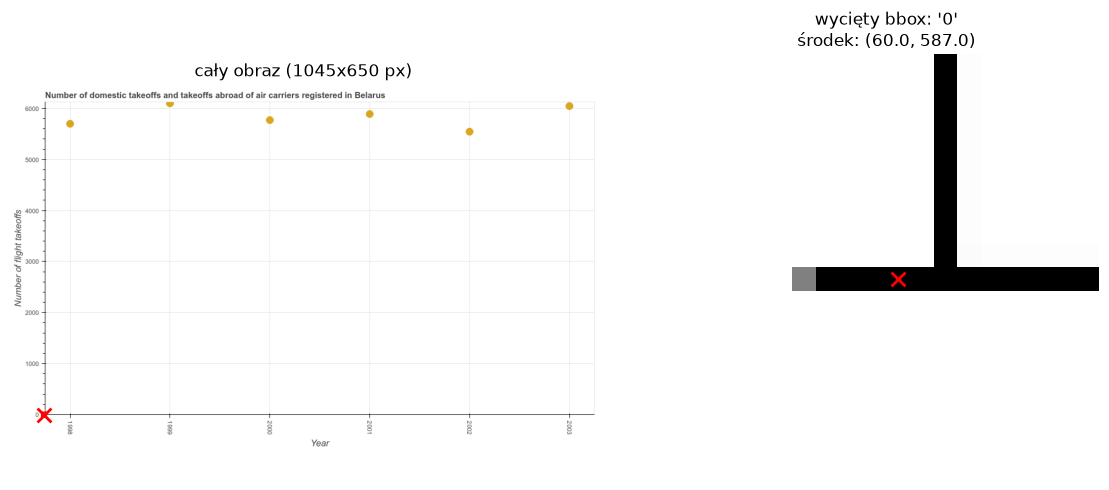

środek bboxa: x=60.0, y=587.0


In [140]:
fig_info = sample_annot["general_figure_info"]
first_y_label = fig_info["y_axis"]["major_ticks"]["values"][0]
bbox = fig_info["y_axis"]["major_ticks"]["bboxes"][0]

bx, by, bw, bh = int(bbox["x"]), int(bbox["y"]), int(bbox["w"]), int(bbox["h"])

cx = bx + bw / 2
cy = by + bh / 2

crop = img_rgb[
    max(0, by - 5) : by + bh + 5,
    max(0, bx - 5) : bx + bw + 5
]

crop_x0 = max(0, bx - 5)
crop_y0 = max(0, by - 5)

crop_cx = cx - crop_x0
crop_cy = cy - crop_y0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

viz_img = img_rgb.copy()
cv2.rectangle(
    viz_img,
    (bx, by),
    (bx + bw, by + bh),
    (255, 0, 0),
    2
)

ax1.imshow(viz_img)
ax1.scatter(cx, cy, color="red", marker="x", s=100, linewidths=2)
ax1.set_title(f"cały obraz ({img.shape[1]}x{img.shape[0]} px)")
ax1.axis("off")

ax2.imshow(crop)
ax2.scatter(
    crop_cx, crop_cy,
    color="red", marker="x", s=100, linewidths=2
)
ax2.set_title(
    f"wycięty bbox: '{first_y_label}'\n"
    f"środek: ({cx:.1f}, {cy:.1f})"
)
ax2.axis("off")

plt.tight_layout()
plt.show()

print(f"środek bboxa: x={cx:.1f}, y={cy:.1f}")


do interpolacji potrzebujemy dwoch punktow z kazdych podzialek, wiec chcelibysmy, zeby bylo jak najdokladniejsze, aby nasza skala się zgadzała. Jednakze, tak jak mozemy zobaczyc na zdjeciu wyzej, pobrane punkty z major ticks nie sa tak dokladne, jak mogloby sie nam wydawac. punkt y wyliczylo nam idealnie, ale mamy problem z punktem x. tak drobny blad, moze nam zepsuc cala skale, wiec zadbajmy o to, aby punkty z podziałki zgadzały się idealnie

sprobujmy wykorzystać informacje o glownej linii osi wykresu, zapisane w pliku JSON jako klucz 'rule'.

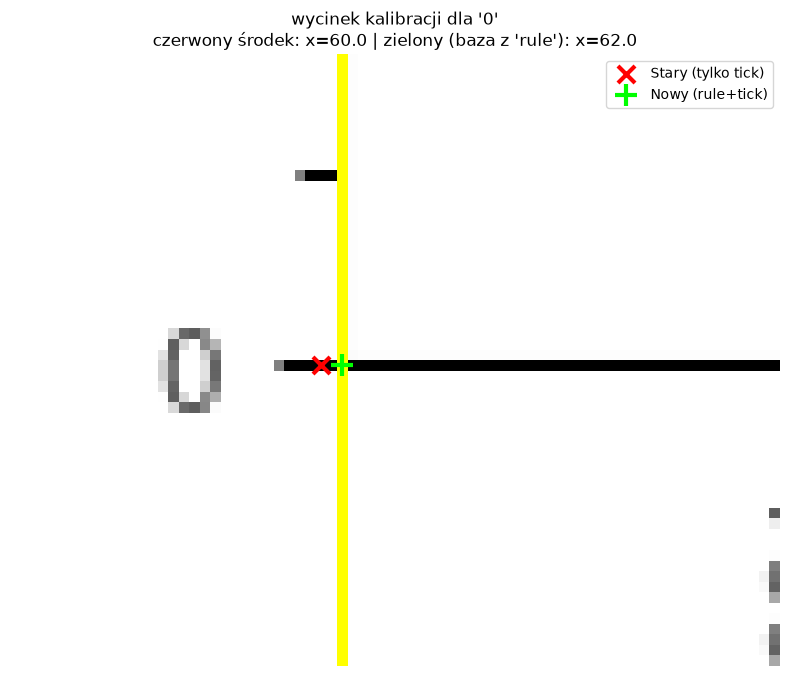

In [141]:
y_rule = fig_info["y_axis"]["rule"]["bbox"]
y_tick = fig_info["y_axis"]["major_ticks"]["bboxes"][0]
first_y_label = fig_info["y_axis"]["major_ticks"]["values"][0]

old_cx = y_tick["x"] + y_tick["w"] / 2
old_cy = y_tick["y"] + y_tick["h"] / 2

perfect_cx = y_rule["x"] + y_rule["w"] / 2
perfect_cy = y_tick["y"] + y_tick["h"] / 2

by, bh = int(y_tick["y"]), int(y_tick["h"])
bx, bw = int(y_tick["x"]), int(y_tick["w"])

crop_y0 = max(0, by - 25)
crop_y1 = by + bh + 25
crop_x0 = max(0, bx - 25)
crop_x1 = bx + bw + 40

crop = img_rgb[crop_y0:crop_y1, crop_x0:crop_x1].copy()

crop_old_cx = old_cx - crop_x0
crop_old_cy = old_cy - crop_y0

crop_perfect_cx = perfect_cx - crop_x0
crop_perfect_cy = perfect_cy - crop_y0

rule_x_in_crop = (y_rule["x"] + y_rule["w"] / 2) - crop_x0
cv2.line(crop, (int(rule_x_in_crop), 0), (int(rule_x_in_crop), crop.shape[0]), (255, 255, 0), 1)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(crop)

ax.scatter(crop_old_cx, crop_old_cy, color="red", marker="x", s=150, linewidths=3, label="Stary (tylko tick)")

ax.scatter(crop_perfect_cx, crop_perfect_cy, color="lime", marker="+", s=250, linewidths=3, label="Nowy (rule+tick)")

ax.set_title(
    f"wycinek kalibracji dla '{first_y_label}'\n"
    f"czerwony środek: x={old_cx:.1f} | zielony (baza z 'rule'): x={perfect_cx:.1f}"
)
ax.legend(loc="upper right")
ax.axis("off")

plt.tight_layout()
plt.show()

jak widzimy, pobralismy wspolrzedną X bezposrednio z bazy osi 'y_rule', ktora jest wysrodkowana i idealnie prosta dla calej osi Y,
współrzędną Y zostawiamy bez zmian, pobierając ją z 'major_ticks', bo ta wartosc wylicza sie poprawnie.
Po połączeniu, udało nam się znaleźć idealny punkt referencyjny, widoczny na wykresie jako zielony plus

zobaczmy teraz, czy ta metoda jest skuteczna dla wszystkich punktow na podzialkach

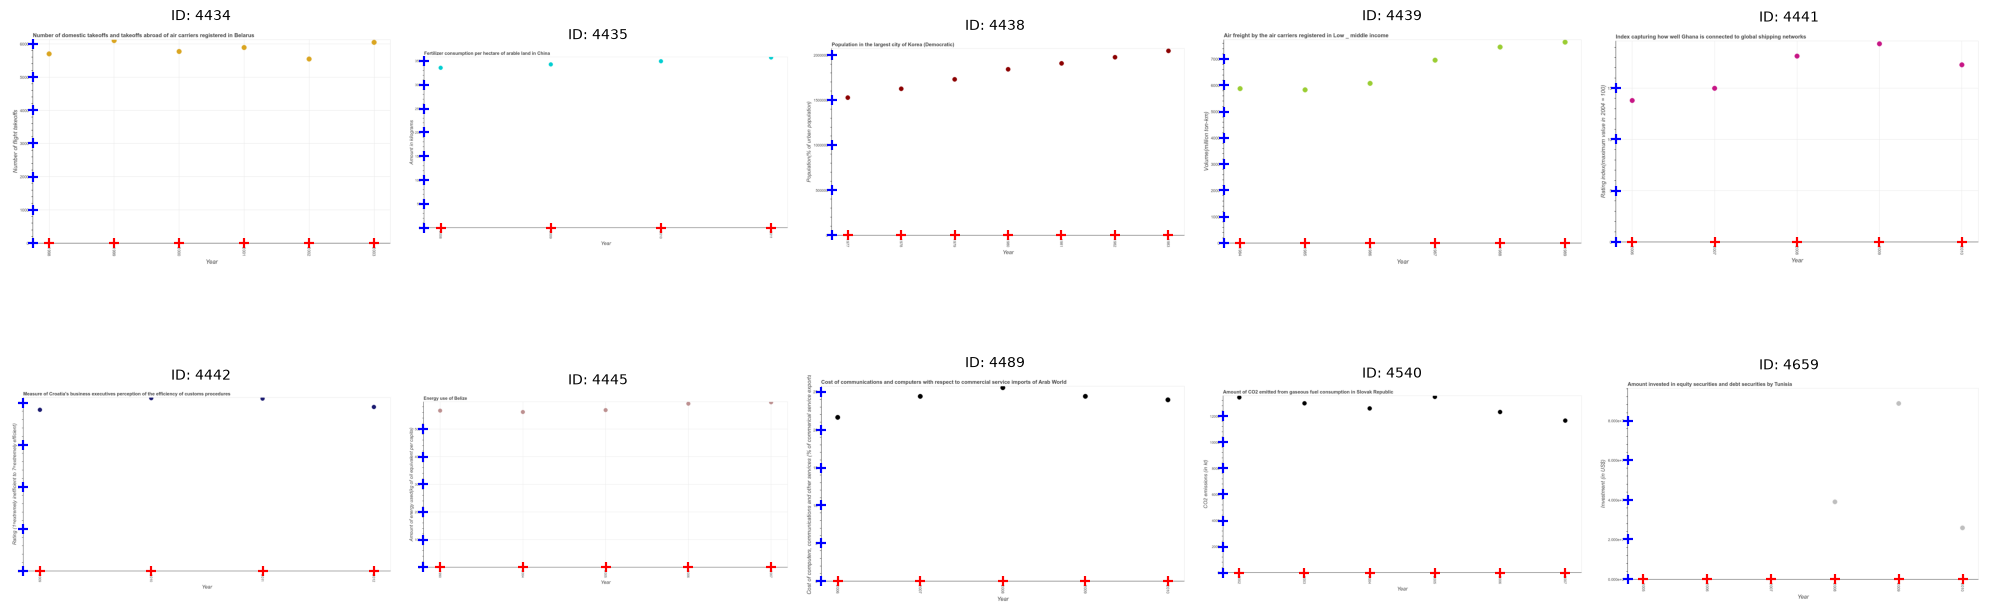

In [142]:
def extract_calibration_points(fig_info):
    y_rule = fig_info["y_axis"]["rule"]["bbox"]
    base_x = y_rule["x"] + y_rule["w"] / 2
    
    y_ticks = fig_info["y_axis"]["major_ticks"]["bboxes"]
    y_points = [(base_x, t["y"] + t["h"] / 2) for t in y_ticks]

    x_rule = fig_info["x_axis"]["rule"]["bbox"]
    base_y = x_rule["y"] + x_rule["h"] / 2
    
    x_ticks = fig_info["x_axis"]["major_ticks"]["bboxes"]
    x_points = [(t["x"] + t["w"] / 2, base_y) for t in x_ticks]

    return x_points, y_points


annot_dict = {str(sample["image_index"]): sample for sample in dev_data["samples"]}

rows, cols = 2, 5
fig, axes = plt.subplots(rows, cols, figsize=(20, 8))
axes = axes.flatten()

for i, dev_id in enumerate(dev_ids[:rows * cols]):
    ax = axes[i]
    img_bgr = dev_images.get(dev_id)

    if img_bgr is not None:
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        sample_annot = annot_dict.get(str(dev_id))
        
        if sample_annot:
            x_points, y_points = extract_calibration_points(sample_annot["general_figure_info"])

            for px, py in y_points:
                ax.scatter(px, py, color="blue", marker="+", s=60, linewidths=1.5)

            for px, py in x_points:
                ax.scatter(px, py, color="red", marker="+", s=60, linewidths=1.5)

        ax.imshow(img_rgb)
        ax.set_title(f"ID: {dev_id}", fontsize=10)
    else:
        ax.text(0.5, 0.5, "Brak obrazu", ha="center", va="center")

    ax.axis("off")

for j in range(len(dev_ids[:rows * cols]), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

udalo sie!! wszystkie punkty na podzialkach zostaly prawidlowo odczytane
zatem zostajemy przy metodzie połączenia punktów z 'rule' i 'major_ticks'


wykorzystajmy teraz interpolacje liniowa, do przeliczenia polozenia punktow w pikselach na wartosci na osiach



najpierw sobie wyprintujmy wszystkie punkty zczytane przez komputer (w pikselach)

In [143]:
dev_pixels = {
    idx: [{"x": cx, "y": cy} for cx, cy in detect_dots(dev_images[idx])]
    for idx in dev_ids
}

for idx in dev_ids:
    pts = dev_pixels[idx]
    print(f"ID {idx} | liczba punktów: {len(pts)} | Punkty: {pts}")

ID 4434 | liczba punktów: 6 | Punkty: [{'x': 106, 'y': 69}, {'x': 284, 'y': 34}, {'x': 462, 'y': 62}, {'x': 639, 'y': 51}, {'x': 817, 'y': 83}, {'x': 995, 'y': 37}]
ID 4435 | liczba punktów: 4 | Punkty: [{'x': 109, 'y': 65}, {'x': 468, 'y': 54}, {'x': 827, 'y': 44}, {'x': 1186, 'y': 34}]
ID 4438 | liczba punktów: 7 | Punkty: [{'x': 130, 'y': 176}, {'x': 289, 'y': 150}, {'x': 448, 'y': 122}, {'x': 608, 'y': 92}, {'x': 767, 'y': 74}, {'x': 926, 'y': 56}, {'x': 1086, 'y': 37}]
ID 4439 | liczba punktów: 6 | Punkty: [{'x': 106, 'y': 164}, {'x': 284, 'y': 167}, {'x': 462, 'y': 149}, {'x': 640, 'y': 86}, {'x': 818, 'y': 50}, {'x': 996, 'y': 36}]
ID 4441 | liczba punktów: 5 | Punkty: [{'x': 94, 'y': 195}, {'x': 322, 'y': 161}, {'x': 550, 'y': 72}, {'x': 779, 'y': 38}, {'x': 1007, 'y': 96}]
ID 4442 | liczba punktów: 4 | Punkty: [{'x': 95, 'y': 69}, {'x': 452, 'y': 34}, {'x': 810, 'y': 35}, {'x': 1167, 'y': 60}]
ID 4445 | liczba punktów: 5 | Punkty: [{'x': 111, 'y': 60}, {'x': 389, 'y': 64}, {'x

sprawdzmy jeszcze, czy te wyliczenia są trafne

In [144]:
def calculate_pixel_tp_fp_fn(pred_pts, gt_pts, img_w, img_h, tol=0.02):
    num_pred = len(pred_pts)
    num_gt = len(gt_pts)

    if num_gt == 0 and num_pred == 0:
        return 0, 0, 0
    if num_pred == 0:
        return 0, 0, num_gt
    if num_gt == 0:
        return 0, num_pred, 0

    cost_matrix = np.zeros((num_pred, num_gt))

    for i, p in enumerate(pred_pts):
        px, py = p["x"], p["y"]
        for j, (gx, gy) in enumerate(gt_pts):
            dx_norm = abs(px - gx) / img_w
            dy_norm = abs(py - gy) / img_h

            if dx_norm <= tol and dy_norm <= tol:
                cost_matrix[i, j] = np.hypot(dx_norm, dy_norm)
            else:
                cost_matrix[i, j] = 100.0

    pred_ind, gt_ind = linear_sum_assignment(cost_matrix)

    tp = 0
    for p_idx, g_idx in zip(pred_ind, gt_ind):
        px, py = pred_pts[p_idx]["x"], pred_pts[p_idx]["y"]
        gx, gy = gt_pts[g_idx]

        dx_norm = abs(px - gx) / img_w
        dy_norm = abs(py - gy) / img_h

        if dx_norm <= tol and dy_norm <= tol:
            tp += 1

    fp = num_pred - tp
    fn = num_gt - tp

    return tp, fp, fn


results_pixel_tp_fp_fn = {}

total_tp_pix = 0
total_fp_pix = 0
total_fn_pix = 0

print(
    f"{'ID':<6} | {'Wykryte (Pred)':<14} | {'Prawdziwe (GT)':<14} | {'TP':<4} |"
    f" {'FP':<4} | {'FN':<4}"
)
print("-" * 60)

for dev_id in dev_ids:
    sample_annot = annot_dict.get(str(dev_id), {})
    img = dev_images[dev_id]
    img_h, img_w = img.shape[:2]

    pred_pts = dev_pixels.get(dev_id, [])

    gt_pts = []
    if "models" in sample_annot:
        for model in sample_annot["models"]:
            if "bboxes" in model:
                for b in model["bboxes"]:
                    cx = b["x"] + b["w"] / 2
                    cy = b["y"] + b["h"] / 2
                    gt_pts.append((cx, cy))

    tp, fp, fn = calculate_pixel_tp_fp_fn(
        pred_pts, gt_pts, img_w, img_h, tol=0.02
    )
    results_pixel_tp_fp_fn[dev_id] = {"TP": tp, "FP": fp, "FN": fn}

    total_tp_pix += tp
    total_fp_pix += fp
    total_fn_pix += fn

    print(
        f"{dev_id:<6} | {len(pred_pts):<14} | {len(gt_pts):<14} | {tp:<4} |"
        f" {fp:<4} | {fn:<4}"
    )

print("=" * 60)
print(
    f"SUMA CAŁKOWITA (PIKSELE): TP = {total_tp_pix}, FP = {total_fp_pix}, FN ="
    f" {total_fn_pix}"
)

ID     | Wykryte (Pred) | Prawdziwe (GT) | TP   | FP   | FN  
------------------------------------------------------------
4434   | 6              | 6              | 6    | 0    | 0   
4435   | 4              | 4              | 4    | 0    | 0   
4438   | 7              | 7              | 7    | 0    | 0   
4439   | 6              | 6              | 6    | 0    | 0   
4441   | 5              | 5              | 5    | 0    | 0   
4442   | 4              | 4              | 4    | 0    | 0   
4445   | 5              | 5              | 5    | 0    | 0   
4489   | 5              | 5              | 5    | 0    | 0   
4540   | 6              | 6              | 6    | 0    | 0   
4659   | 3              | 3              | 3    | 0    | 0   
SUMA CAŁKOWITA (PIKSELE): TP = 51, FP = 0, FN = 0


samo wykrywanie punktów na obrazku dziala wręcz idealnie, wszystkie punkty zostały trafnie zidentyfikowane!

teraz korzystając z wyliczonych punktów, będziemy wyliczać ich wartości na wykresie

wiemy, ze oś Y to zmienna ciągła, więc do niej wykorzystamy interpolację liniową, aby przeliczyć wysokość piksela na dokładną wartość liczbową

za to oś X to zmienna kategoryczna, gdzie kropki stoją w pionowych kolumnach i nie mamy tam wartości pośrednich, typu 2006.54
zatem przeliczeniem dla osi X będzie wyznaczenie najblizszego sąsiada (czyli przypisanie kropki do kolumny, do której ma najmniej pikseli w poziomie)


In [145]:
def map_pixels_to_actual_values(pixels_list, fig_info):
    if not pixels_list:
        return []

    y_ticks = fig_info["y_axis"]["major_ticks"]
    y_bboxes = y_ticks["bboxes"]
    y_vals = [float(v) for v in y_ticks["values"]]
    y_pixs = [b["y"] + b["h"] / 2 for b in y_bboxes]

    sorted_y = sorted(zip(y_pixs, y_vals), key=lambda p: p[0])
    y_pix_sorted = [p[0] for p in sorted_y]
    y_val_sorted = [p[1] for p in sorted_y]

    x_labels_info = fig_info["x_axis"]["major_labels"]
    x_labels_text = x_labels_info["values"]
    x_labels_bboxes = x_labels_info["bboxes"]

    unique_x = {}
    for val, bbox in zip(x_labels_text, x_labels_bboxes):
        cx_label = bbox["x"] + bbox["w"] / 2
        unique_x[round(cx_label, 1)] = val

    x_pix_unique = list(unique_x.keys())

    mapped_points = []
    for pt in pixels_list:
        cx, cy = pt["x"], pt["y"]

        y_val = float(np.interp(cy, y_pix_sorted, y_val_sorted))

        closest_px = min(x_pix_unique, key=lambda px: abs(cx - px))
        x_val = unique_x[closest_px]

        mapped_points.append({"x": x_val, "y": round(y_val, 3)})

    return mapped_points


dev_mapped_actual_values = {}

for dev_id in dev_ids:
    sample_annot = annot_dict.get(str(dev_id))
    if sample_annot and "general_figure_info" in sample_annot:
        fig_info = sample_annot["general_figure_info"]
        dev_mapped_actual_values[dev_id] = map_pixels_to_actual_values(
            dev_pixels[dev_id], fig_info
        )
print("Wyliczone wartości:\n")
for idx in dev_ids:
    print(f"ID {idx}: {dev_mapped_actual_values[idx]}")

Wyliczone wartości:

ID 4434: [{'x': '1998', 'y': 5703.297}, {'x': '1999', 'y': 6000.0}, {'x': '2000', 'y': 5780.22}, {'x': '2001', 'y': 5901.099}, {'x': '2002', 'y': 5549.451}, {'x': '2003', 'y': 6000.0}]
ID 4435: [{'x': '2008', 'y': 335.897}, {'x': '2009', 'y': 342.949}, {'x': '2010', 'y': 349.359}, {'x': '2011', 'y': 350.0}]
ID 4438: [{'x': '1977', 'y': 1529850.746}, {'x': '1978', 'y': 1626865.672}, {'x': '1979', 'y': 1731343.284}, {'x': '1980', 'y': 1843283.582}, {'x': '1981', 'y': 1910447.761}, {'x': '1982', 'y': 1977611.94}, {'x': '1983', 'y': 2000000.0}]
ID 4439: [{'x': '1984', 'y': 5875.0}, {'x': '1985', 'y': 5833.333}, {'x': '1986', 'y': 6083.333}, {'x': '1987', 'y': 6958.333}, {'x': '1988', 'y': 7000.0}, {'x': '1989', 'y': 7000.0}]
ID 4441: [{'x': '2006', 'y': 13.803}, {'x': '2007', 'y': 15.0}, {'x': '2008', 'y': 15.0}, {'x': '2009', 'y': 15.0}, {'x': '2010', 'y': 15.0}]
ID 4442: [{'x': '2009', 'y': 3.837}, {'x': '2010', 'y': 4.0}, {'x': '2011', 'y': 4.0}, {'x': '2012', 'y': 

teraz sobie pobierzemy faktyczne wartości, zeby moc sprawdzic jakosc

In [146]:
def get_gt_values_with_labels(sample_annot):
    if "general_figure_info" not in sample_annot or "models" not in sample_annot:
        return []

    fig_info = sample_annot["general_figure_info"]

    x_ticks_vals = fig_info["x_axis"]["major_ticks"]["values"]
    x_labels_vals = fig_info["x_axis"]["major_labels"]["values"]
    index_to_label = dict(zip(x_ticks_vals, x_labels_vals))

    gt_points = []

    for model in sample_annot["models"]:
        for x_idx, y_val in zip(model["x"], model["y"]):
            actual_x = index_to_label.get(x_idx, x_idx)

            if str(actual_x).isdigit():
                actual_x = int(actual_x)

            gt_points.append({"x": actual_x, "y": round(float(y_val), 3)})

    return gt_points

dev_gt_actual_values = {}

for dev_id in dev_ids:
    sample_annot = annot_dict.get(str(dev_id))
    if sample_annot:
        dev_gt_actual_values[dev_id] = get_gt_values_with_labels(sample_annot)

print("Prawdziwe wartości z JSON:\n")
for idx in dev_ids:
    print(f"ID {idx}: {dev_gt_actual_values[idx]}")

Prawdziwe wartości z JSON:

ID 4434: [{'x': 1998, 'y': 5700.0}, {'x': 1999, 'y': 6100.0}, {'x': 2000, 'y': 5772.0}, {'x': 2001, 'y': 5891.0}, {'x': 2002, 'y': 5545.0}, {'x': 2003, 'y': 6047.0}]
ID 4435: [{'x': 2008, 'y': 335.584}, {'x': 2009, 'y': 342.731}, {'x': 2010, 'y': 349.347}, {'x': 2011, 'y': 357.276}]
ID 4438: [{'x': 1977, 'y': 1527371.0}, {'x': 1978, 'y': 1625725.0}, {'x': 1979, 'y': 1730413.0}, {'x': 1980, 'y': 1842000.0}, {'x': 1981, 'y': 1907720.0}, {'x': 1982, 'y': 1975881.0}, {'x': 1983, 'y': 2046476.0}]
ID 4439: [{'x': 1984, 'y': 5877.4}, {'x': 1985, 'y': 5830.4}, {'x': 1986, 'y': 6077.3}, {'x': 1987, 'y': 6960.0}, {'x': 1988, 'y': 7459.4}, {'x': 1989, 'y': 7646.2}]
ID 4441: [{'x': 2006, 'y': 13.8}, {'x': 2007, 'y': 14.99}, {'x': 2008, 'y': 18.13}, {'x': 2009, 'y': 19.33}, {'x': 2010, 'y': 17.28}]
ID 4442: [{'x': 2009, 'y': 3.833}, {'x': 2010, 'y': 4.11}, {'x': 2011, 'y': 4.1}, {'x': 2012, 'y': 3.9}]
ID 4445: [{'x': 1990, 'y': 566.339}, {'x': 2004, 'y': 561.421}, {'x': 

przeliczylismy wszystkie punkty, na wartosci na osiach, sprawdzmy teraz, jak trafne są te przeliczenia

In [147]:
def calculate_tp_fp_fn(pred_points, gt_points, y_range, tol=0.02):
    num_pred = len(pred_points)
    num_gt = len(gt_points)

    if num_gt == 0 and num_pred == 0:
        return 0, 0, 0
    if num_pred == 0:
        return 0, 0, num_gt
    if num_gt == 0:
        return 0, num_pred, 0

    cost_matrix = np.zeros((num_pred, num_gt))

    for i, p in enumerate(pred_points):
        for j, g in enumerate(gt_points):
            x_match = str(p["x"]).strip() == str(g["x"]).strip()

            err_y = abs(p["y"] - g["y"]) / y_range if y_range > 0 else 0.0

            if x_match and err_y <= tol:
                cost_matrix[i, j] = err_y
            else:
                cost_matrix[i, j] = 100.0

    pred_ind, gt_ind = linear_sum_assignment(cost_matrix)

    tp = 0
    for p_idx, g_idx in zip(pred_ind, gt_ind):
        p, g = pred_points[p_idx], gt_points[g_idx]

        x_match = str(p["x"]).strip() == str(g["x"]).strip()
        err_y = abs(p["y"] - g["y"]) / y_range if y_range > 0 else 0.0

        if x_match and err_y <= tol:
            tp += 1

    fp = num_pred - tp
    fn = num_gt - tp

    return tp, fp, fn


results_tp_fp_fn = {}

total_tp = 0
total_fp = 0
total_fn = 0

print(
    f"{'ID':<6} | {'Wykryte (Pred)':<14} | {'Prawdziwe (GT)':<14} | {'TP':<4} |"
    f" {'FP':<4} | {'FN':<4}"
)
print("-" * 60)

for dev_id in dev_ids:
    sample_annot = annot_dict.get(str(dev_id))
    if not sample_annot or "general_figure_info" not in sample_annot:
        continue

    fig_info = sample_annot["general_figure_info"]

    y_vals = [float(v) for v in fig_info["y_axis"]["major_ticks"]["values"]]
    y_range = max(y_vals) - min(y_vals) if y_vals else 1.0

    preds = dev_mapped_actual_values.get(dev_id, [])
    gts = dev_gt_actual_values.get(dev_id, [])

    tp, fp, fn = calculate_tp_fp_fn(preds, gts, y_range, tol=0.02)

    results_tp_fp_fn[dev_id] = {"TP": tp, "FP": fp, "FN": fn}

    total_tp += tp
    total_fp += fp
    total_fn += fn

    print(
        f"{dev_id:<6} | {len(preds):<14} | {len(gts):<14} | {tp:<4} | {fp:<4} |"
        f" {fn:<4}"
    )

print("=" * 60)
print(f"SUMA CAŁKOWITA: TP = {total_tp}, FP = {total_fp}, FN = {total_fn}")

ID     | Wykryte (Pred) | Prawdziwe (GT) | TP   | FP   | FN  
------------------------------------------------------------
4434   | 6              | 6              | 6    | 0    | 0   
4435   | 4              | 4              | 3    | 1    | 1   
4438   | 7              | 7              | 6    | 1    | 1   
4439   | 6              | 6              | 4    | 2    | 2   
4441   | 5              | 5              | 2    | 3    | 3   
4442   | 4              | 4              | 2    | 2    | 2   
4445   | 5              | 5              | 0    | 5    | 5   
4489   | 5              | 5              | 4    | 1    | 1   
4540   | 6              | 6              | 1    | 5    | 5   
4659   | 3              | 6              | 2    | 1    | 4   
SUMA CAŁKOWITA: TP = 30, FP = 21, FN = 24


In [148]:
def evaluate_chart_predictions_full(
    pred_points, gt_points, y_range, x_range=None, tol=0.02
):

    num_pred = len(pred_points)
    num_gt = len(gt_points)

    if num_pred == 0 or num_gt == 0:
        tp = 0
        fp = num_pred
        fn = num_gt
        return {
            "tp": 0,
            "fp": fp,
            "fn": fn,
            "precision": 0.0,
            "recall": 0.0,
            "f1": 0.0,
            "matches": 0,
            "mae_x_pct": None,
            "mae_y_pct": None,  
        }

    cost_matrix = np.full((num_pred, num_gt), 1000.0)

    for i, p in enumerate(pred_points):
        for j, g in enumerate(gt_points):
            x_match = str(p["x"]).strip() == str(g["x"]).strip()
            err_y = abs(p["y"] - g["y"]) / y_range if y_range > 0 else 0.0

            if x_match and err_y <= tol:
                cost_matrix[i, j] = err_y

    pred_ind, gt_ind = linear_sum_assignment(cost_matrix)

    matched_pairs = []
    for p_idx, g_idx in zip(pred_ind, gt_ind):
        p = pred_points[p_idx]
        g = gt_points[g_idx]

        x_match = str(p["x"]).strip() == str(g["x"]).strip()
        err_y = abs(p["y"] - g["y"]) / y_range if y_range > 0 else 0.0

        if x_match and err_y <= tol:
            matched_pairs.append((p, g, err_y))

    tp = len(matched_pairs)
    fp = num_pred - tp
    fn = num_gt - tp

    precision = tp / num_pred if num_pred > 0 else 0.0
    recall = tp / num_gt if num_gt > 0 else 0.0
    f1 = (
        (2 * precision * recall) / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    if tp > 0:
        mae_y_pct = np.mean([pair[2] for pair in matched_pairs]) * 100.0
        mae_x_pct = 0.0  
    else:
        mae_y_pct = None
        mae_x_pct = None

    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "matches": tp,
        "mae_x_pct": mae_x_pct,
        "mae_y_pct": mae_y_pct,
    }


TOLERANCE = 0.02
all_eval_results = []

print(f"=== RAPORT EWALUACYJNY (Tolerancja: {TOLERANCE * 100}%) ===")
print(
    f"{'ID':<6} | {'Dopasowania':<11} | {'Prec':<6} | {'Rec':<6} | {'F1':<6} |"
    f" {'MAE X (%)':<10} | {'MAE Y (%)':<10}"
)
print("-" * 72)

for dev_id in dev_ids:
    sample_annot = annot_dict.get(str(dev_id))
    if not sample_annot or "general_figure_info" not in sample_annot:
        continue

    fig_info = sample_annot["general_figure_info"]

    y_vals = [float(v) for v in fig_info["y_axis"]["major_ticks"]["values"]]
    y_range = max(y_vals) - min(y_vals) if y_vals else 1.0

    preds = dev_mapped_actual_values.get(dev_id, [])
    gts = dev_gt_actual_values.get(dev_id, [])

    res = evaluate_chart_predictions_full(
        preds, gts, y_range=y_range, tol=TOLERANCE
    )
    all_eval_results.append(res)

    mae_x_str = (
        f"{res['mae_x_pct']:.2f}%" if res["mae_x_pct"] is not None else "N/A"
    )
    mae_y_str = (
        f"{res['mae_y_pct']:.3f}%" if res["mae_y_pct"] is not None else "N/A"
    )

    print(
        f"{dev_id:<6} | {res['matches']:<11} | {res['precision']:<6.2f} |"
        f" {res['recall']:<6.2f} | {res['f1']:<6.2f} | {mae_x_str:<10} |"
        f" {mae_y_str:<10}"
    )

# Wyliczenie metryk podsumowujących
tot_tp = sum(r["tp"] for r in all_eval_results)
tot_fp = sum(r["fp"] for r in all_eval_results)
tot_fn = sum(r["fn"] for r in all_eval_results)

global_prec = tot_tp / (tot_tp + tot_fp) if (tot_tp + tot_fp) > 0 else 0.0
global_rec = tot_tp / (tot_tp + tot_fn) if (tot_tp + tot_fn) > 0 else 0.0
global_f1 = (
    (2 * global_prec * global_rec) / (global_prec + global_rec)
    if (global_prec + global_rec) > 0
    else 0.0
)

valid_mae_y = [
    r["mae_y_pct"] for r in all_eval_results if r["mae_y_pct"] is not None
]
mean_mae_y = np.mean(valid_mae_y) if valid_mae_y else None
mean_mae_y_str = f"{mean_mae_y:.3f}%" if mean_mae_y is not None else "N/A"

print("=" * 72)
print(
    f"PODSUMOWANIE ZBIORCZE: TP={tot_tp}, FP={tot_fp}, FN={tot_fn} |"
    f" Dopasowania: {tot_tp}"
)
print(
    f"GLOBALNE METRYKI   : Precision={global_prec:.4f} | Recall={global_rec:.4f}"
    f" | F1-Score={global_f1:.4f}"
)
print(f"ŚREDNI BŁĄD MAE Y  : {mean_mae_y_str}")

=== RAPORT EWALUACYJNY (Tolerancja: 2.0%) ===
ID     | Dopasowania | Prec   | Rec    | F1     | MAE X (%)  | MAE Y (%) 
------------------------------------------------------------------------
4434   | 6           | 1.00   | 1.00   | 1.00   | 0.00%      | 0.481%    
4435   | 3           | 0.75   | 0.75   | 0.75   | 0.00%      | 0.052%    
4438   | 6           | 0.86   | 0.86   | 0.86   | 0.00%      | 0.086%    
4439   | 4           | 0.67   | 0.67   | 0.67   | 0.00%      | 0.047%    
4441   | 2           | 0.40   | 0.40   | 0.40   | 0.00%      | 0.043%    
4442   | 2           | 0.50   | 0.50   | 0.50   | 0.00%      | 0.100%    
4445   | 0           | 0.00   | 0.00   | 0.00   | N/A        | N/A       
4489   | 4           | 0.80   | 0.80   | 0.80   | 0.00%      | 0.027%    
4540   | 1           | 0.17   | 0.17   | 0.17   | 0.00%      | 0.213%    
4659   | 2           | 0.67   | 0.33   | 0.44   | 0.00%      | 0.061%    
PODSUMOWANIE ZBIORCZE: TP=30, FP=21, FN=24 | Dopasowania: 30
GLOBAL

jak widzimy, po kalibracji osi wyniki nie są juz takie obiecujące, jak przed przeliczeniem punktów na wartości na osiach.
zwizualizujmy sobie to wszystko na wykresach, zeby zobaczyć co poszlo niezgodnie z planem

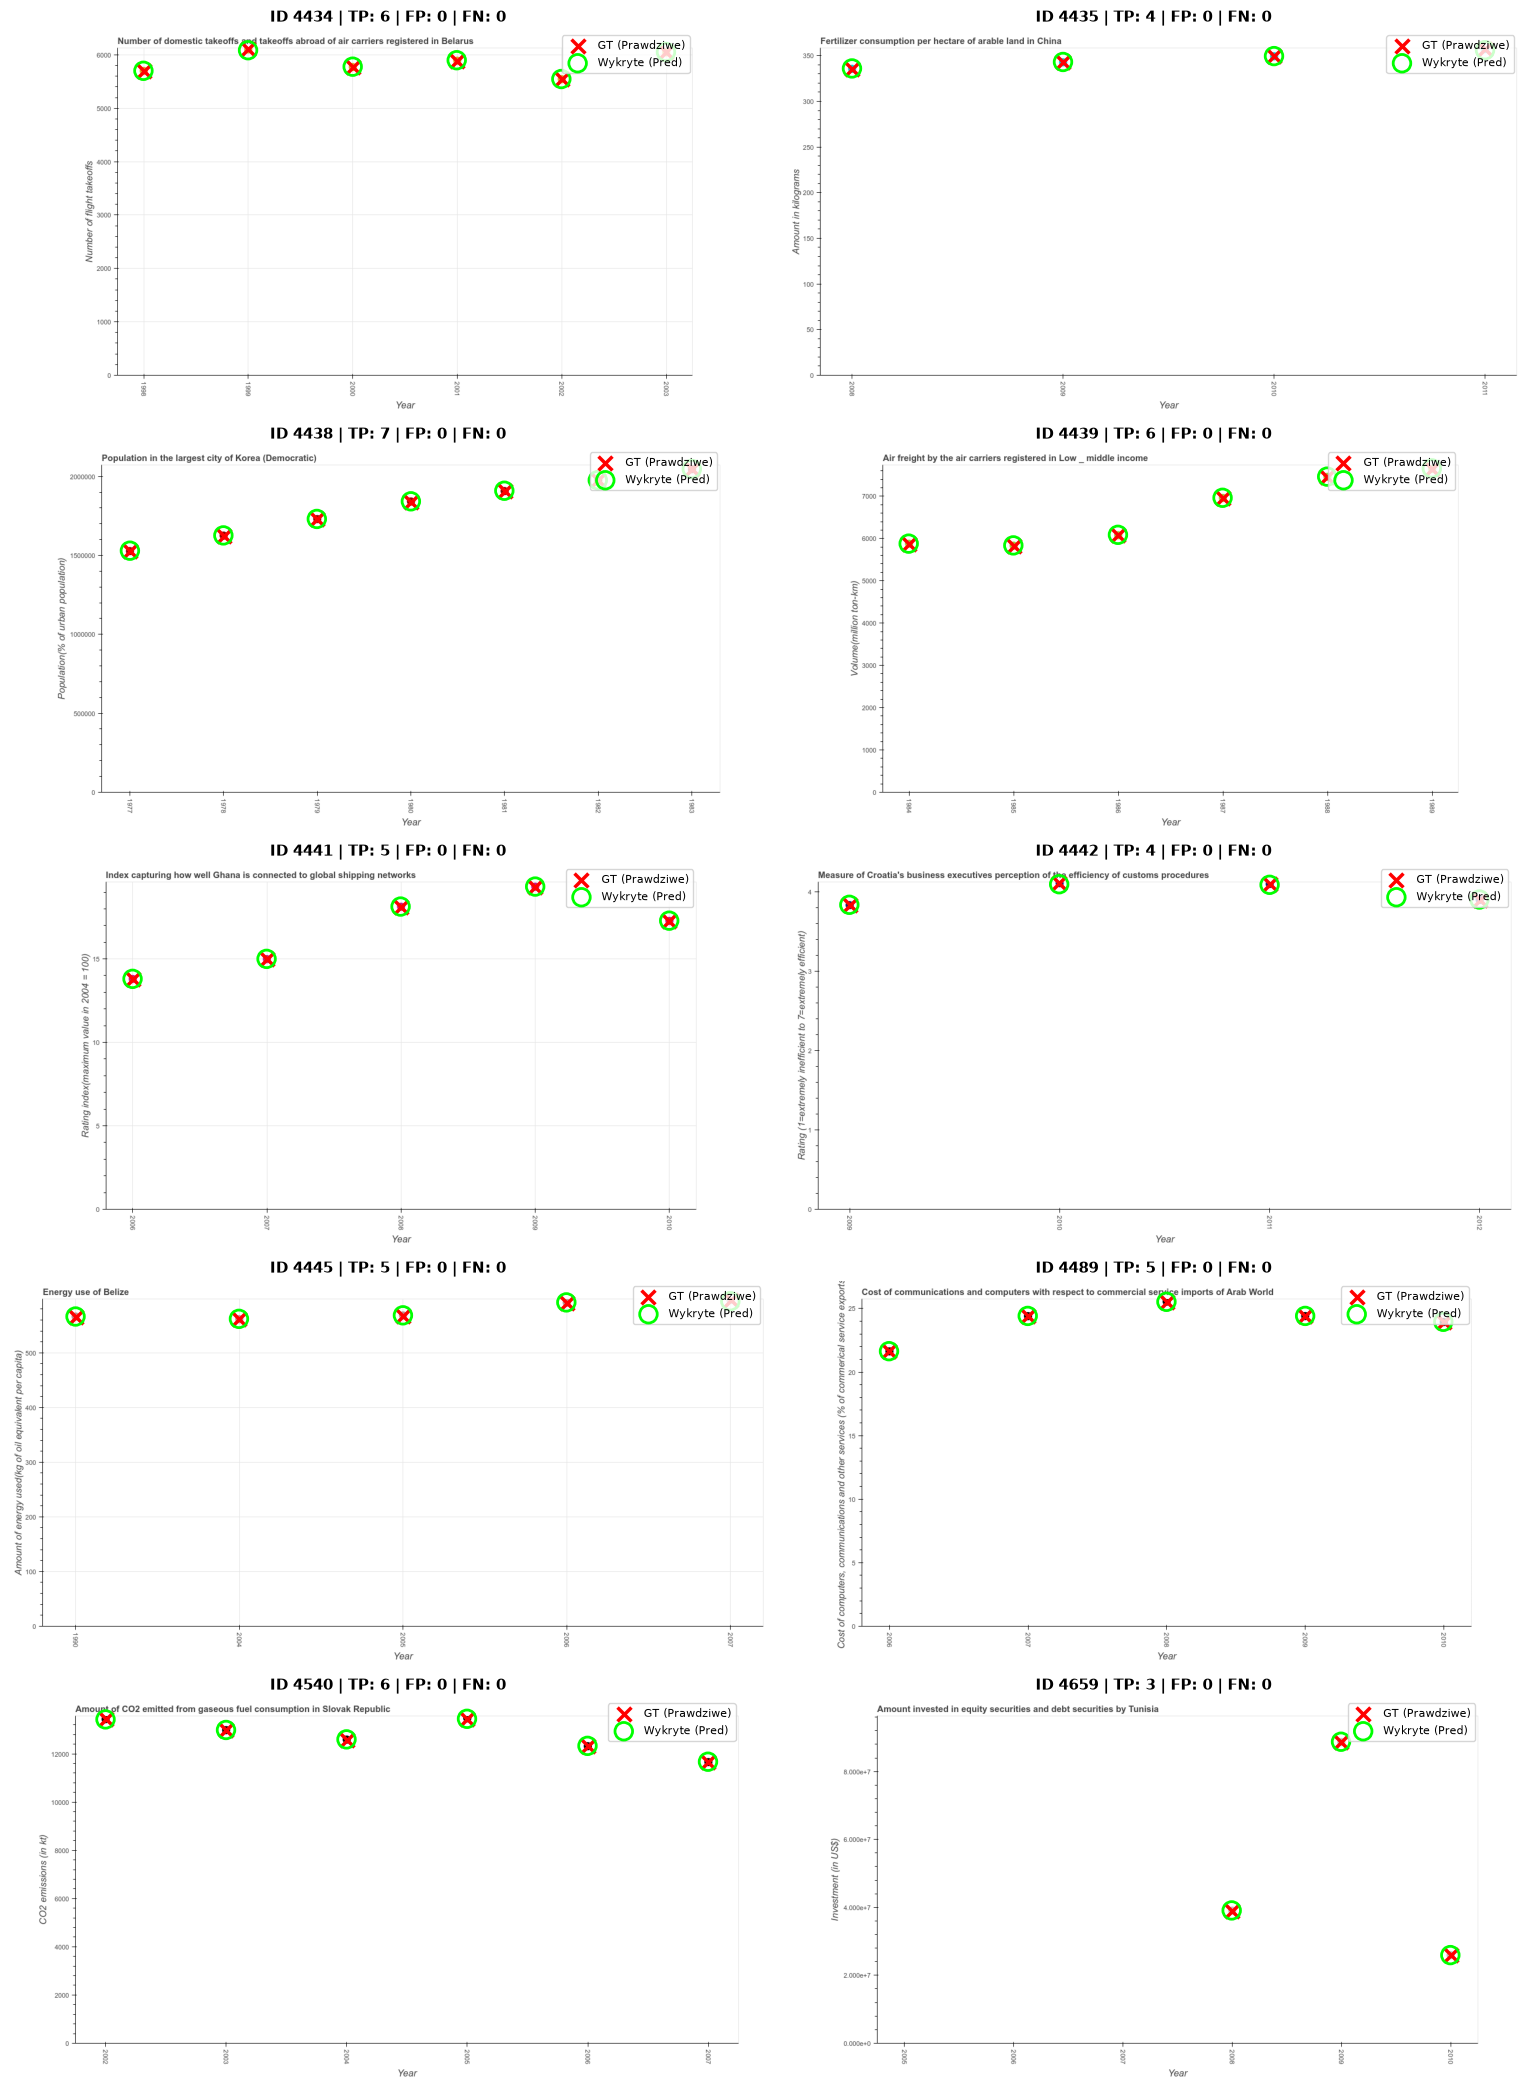

In [149]:
cols = 2
rows = math.ceil(len(dev_ids) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, 4.2 * rows))

if len(dev_ids) == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for idx, dev_id in enumerate(dev_ids):
    ax = axes[idx]

    res = results_pixel_tp_fp_fn.get(dev_id, {"TP": 0, "FP": 0, "FN": 0})
    sample_annot = annot_dict.get(str(dev_id), {})
    img = dev_images[dev_id].copy()

    detected_pts = dev_pixels.get(dev_id, [])

    gt_pts = []
    if "models" in sample_annot:
        for model in sample_annot["models"]:
            if "bboxes" in model:
                for b in model["bboxes"]:
                    cx = b["x"] + b["w"] / 2
                    cy = b["y"] + b["h"] / 2
                    gt_pts.append((cx, cy))

    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

    if gt_pts:
        gt_x = [pt[0] for pt in gt_pts]
        gt_y = [pt[1] for pt in gt_pts]
        ax.scatter(
            gt_x,
            gt_y,
            c="red",
            s=100,
            marker="x",
            linewidths=2.5,
            label="GT (Prawdziwe)",
            zorder=3,
        )

    if detected_pts:
        det_x = [pt["x"] for pt in detected_pts]
        det_y = [pt["y"] for pt in detected_pts]
        ax.scatter(
            det_x,
            det_y,
            edgecolors="lime",
            facecolors="none",
            s=160,
            linewidths=2,
            label="Wykryte (Pred)",
            zorder=4,
        )

    title_color = "darkred" if res["FN"] > 0 else "black"
    ax.set_title(
        f"ID {dev_id} | TP: {res['TP']} | FP: {res['FP']} | FN: {res['FN']}",
        fontsize=11,
        fontweight="bold",
        color=title_color,
    )

    ax.legend(loc="upper right", fontsize=8)
    ax.axis("off")

for j in range(len(dev_ids), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

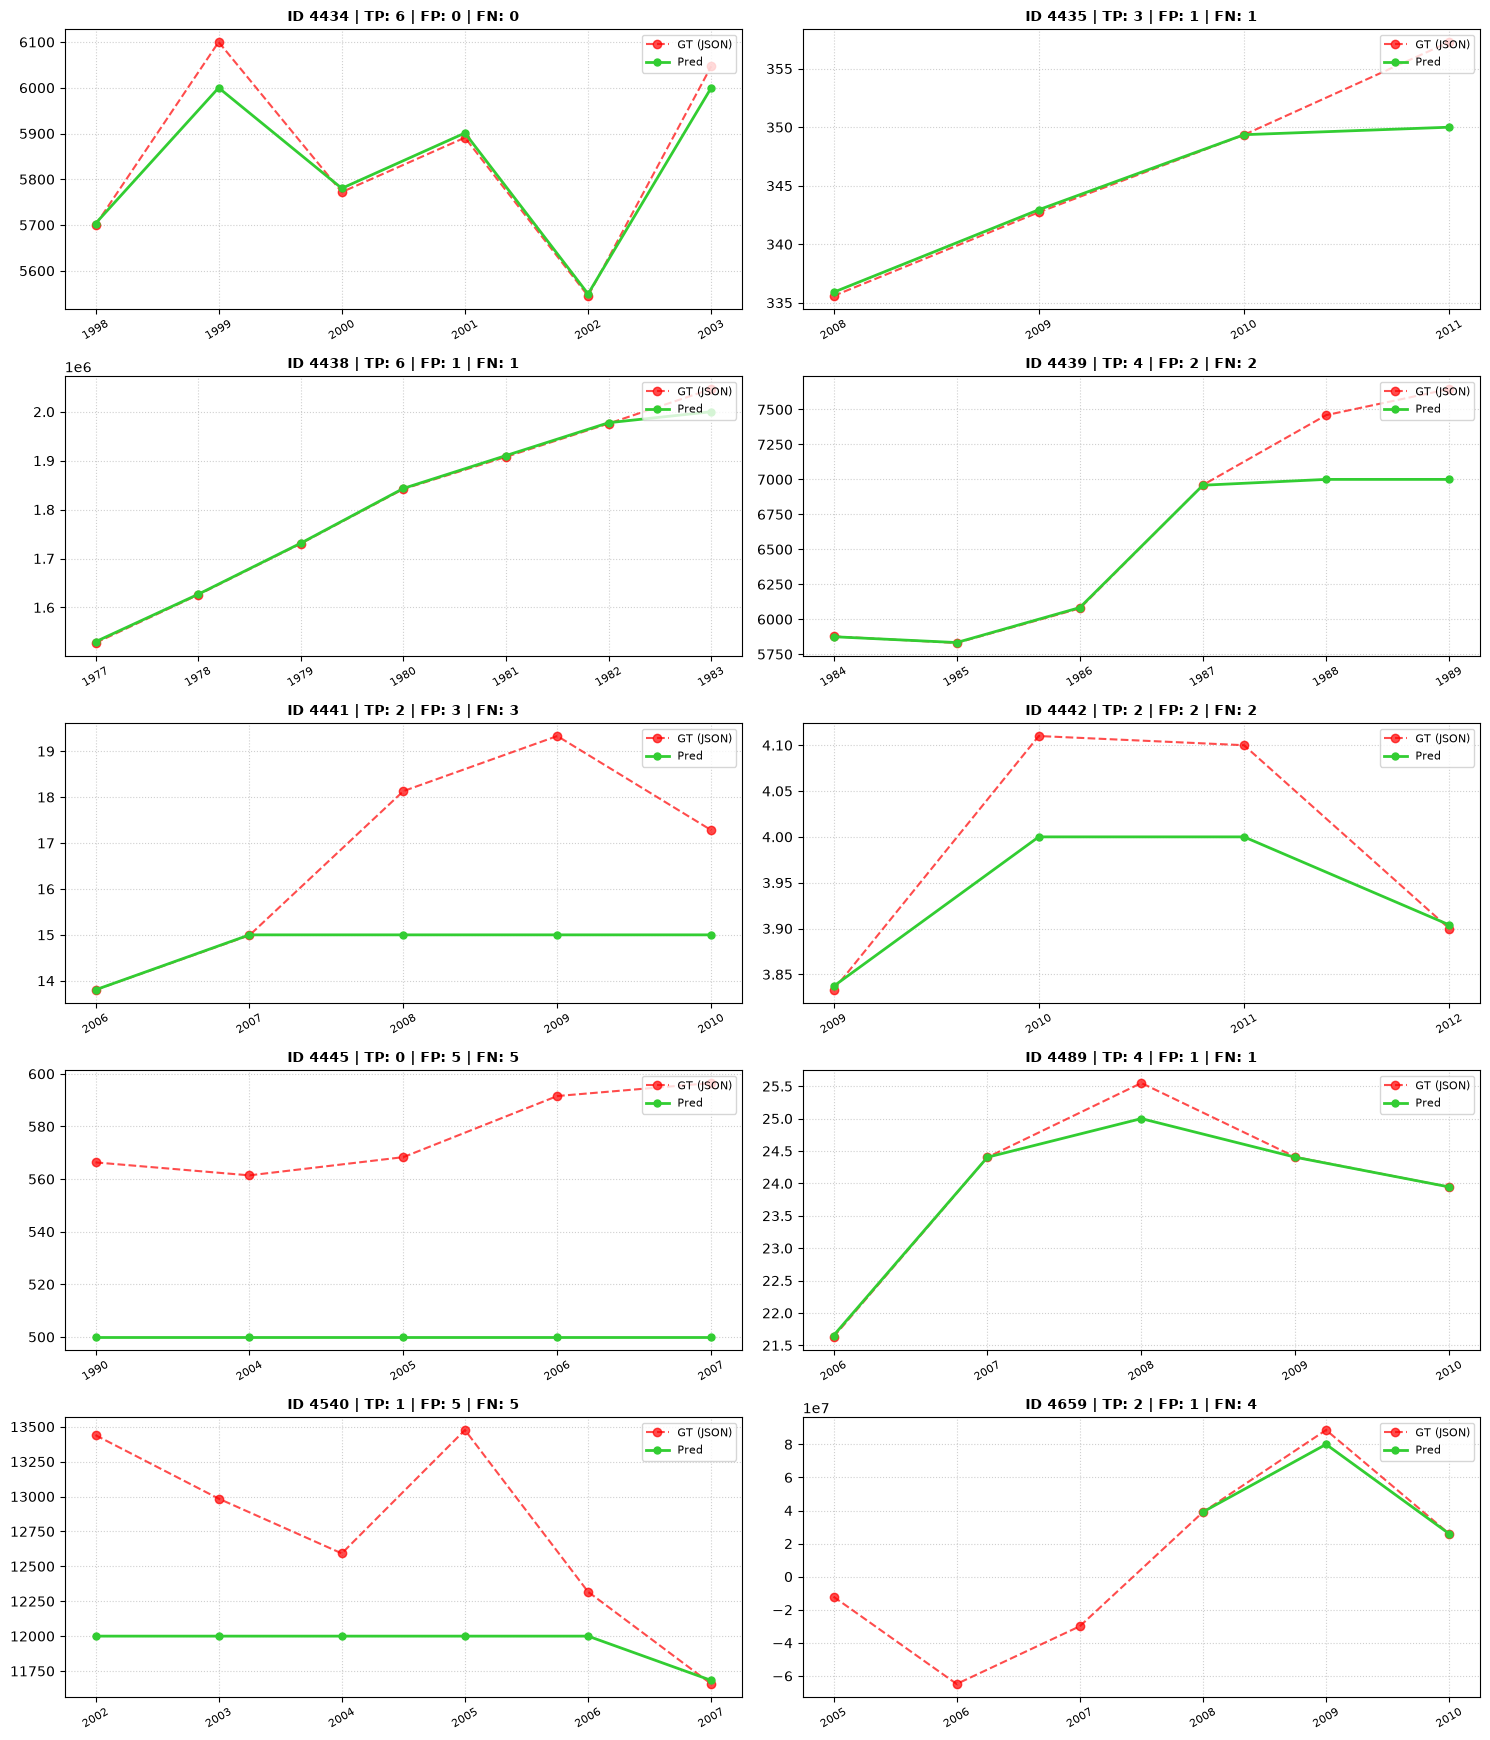

In [150]:
cols = 2
rows = math.ceil(len(dev_ids) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, 3.5 * rows))

if len(dev_ids) == 1:
    axes = [axes]
else:
    axes = axes.flatten()


def sort_key(pt):
    x = pt["x"]
    try:
        return float(x)
    except ValueError:
        return str(x)


for idx, dev_id in enumerate(dev_ids):
    ax = axes[idx]
    preds = dev_mapped_actual_values.get(dev_id, [])
    gts = dev_gt_actual_values.get(dev_id, [])

    preds_sorted = sorted(preds, key=sort_key)
    gts_sorted = sorted(gts, key=sort_key)

    pred_x = [str(pt["x"]) for pt in preds_sorted]
    pred_y = [pt["y"] for pt in preds_sorted]

    gt_x = [str(pt["x"]) for pt in gts_sorted]
    gt_y = [pt["y"] for pt in gts_sorted]

    ax.plot(
        gt_x,
        gt_y,
        "o--",
        color="red",
        label="GT (JSON)",
        markersize=6,
        linewidth=1.5,
        alpha=0.7,
    )

    ax.plot(
        pred_x,
        pred_y,
        "o-",
        color="limegreen",
        label="Pred",
        markersize=5,
        linewidth=2,
    )

    res = results_tp_fp_fn.get(dev_id, {"TP": 0, "FP": 0, "FN": 0})

    ax.set_title(
        f"ID {dev_id} | TP: {res['TP']} | FP: {res['FP']} | FN: {res['FN']}",
        fontsize=10,
        fontweight="bold",
    )
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=8, loc="upper right")
    ax.tick_params(axis="x", rotation=30, labelsize=8)

for j in range(len(dev_ids), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

mysle, ze ta wizualizacja nam calkiem duzo mowi:

1. dla ID: 4659 w 'sample_annotations.json' są dopisane 3 punkty dla ujemnej osi Y, których nie widać na wykresie, z ktorego komputer ma odczytywać punkty, więc dla tego problemu, odfiltrujemy punkty GT, które lezą ponizej dolnej krawędzi osi Y

2. dla ID: 4540, 4445, 4439 wyraźnie widać, ze pionowa linia ogranicza jakby wykres z góry ostatnią widoczną wartością z podziałki, jest to wina klasycznej interpolacji liniowej, dla której w momencie, kiedy coś znajduje się powyzej najwyzszego znacznika osi Y, to np.interp zwraca stałą wartość.
Wobec tego, wiedząc, ze zaleznosc miedzy współrzędną pikselową y, a wartością liczbową na osi Y jest ściśle liniowa, spróbujemy zastosować regresję liniową (np.polyfit) wyznaczoną na podstawie znanych podziałek z 'major_ticks'

3. dotychczasowe mapowanie osi X wyznaczalo srodek ramki tekstowej z major_labels (cx = bbox['x'] + bbox['w'] / 2). przy obroconym tekście (rok jest w kazdym obrocony o 45 stopni), środek prostokąta ulega przesunięciu względem rzeczywistej kreski podziałki. Żeby uniknąć błędnego przypisywania kropek do sąsiednich lat, punkty odniesienia osi X pobierzemy bezposrednio z podzialek 'major_ticks', a etykiety tekstowe przypiszemy do odpowiadających im podziałek

spróbujmy zastosować te rozwiązania

In [151]:
def map_pixels_to_actual_values_2(pixels_list, fig_info):
    if not pixels_list:
        return []

    y_ticks = fig_info["y_axis"]["major_ticks"]
    y_bboxes = y_ticks["bboxes"]
    y_vals = [float(v) for v in y_ticks["values"]]
    y_pixs = [b["y"] + b["h"] / 2 for b in y_bboxes]

    poly_y = np.polyfit(y_pixs, y_vals, 1)

    x_ticks_info = fig_info["x_axis"]["major_ticks"]
    x_ticks_bboxes = x_ticks_info["bboxes"]
    x_labels_text = fig_info["x_axis"]["major_labels"]["values"]

    unique_x = {}
    for val_text, bbox in zip(x_labels_text, x_ticks_bboxes):
        cx_tick = bbox["x"] + bbox["w"] / 2
        unique_x[round(cx_tick, 1)] = val_text

    x_pix_unique = list(unique_x.keys())

    mapped_points = []
    for pt in pixels_list:
        cx, cy = pt["x"], pt["y"]

        y_val = float(np.polyval(poly_y, cy))

        closest_px = min(x_pix_unique, key=lambda px: abs(cx - px))
        x_val = unique_x[closest_px]

        mapped_points.append({"x": x_val, "y": round(y_val, 3)})

    return mapped_points


dev_mapped_actual_values_2 = {}

for dev_id in dev_ids:
    sample_annot = annot_dict.get(str(dev_id))
    if sample_annot and "general_figure_info" in sample_annot:
        fig_info = sample_annot["general_figure_info"]
        dev_mapped_actual_values_2[dev_id] = map_pixels_to_actual_values_2(
            dev_pixels[dev_id], fig_info
        )

print("Wyliczone wartości v2 (po poprawkach):\n")
for idx in dev_ids:
    print(f"ID {idx}: {dev_mapped_actual_values_2[idx]}")

Wyliczone wartości v2 (po poprawkach):

ID 4434: [{'x': '1998', 'y': 5703.378}, {'x': '1999', 'y': 6088.901}, {'x': '2000', 'y': 5780.483}, {'x': '2001', 'y': 5901.647}, {'x': '2002', 'y': 5549.169}, {'x': '2003', 'y': 6055.856}]
ID 4435: [{'x': '2008', 'y': 336.0}, {'x': '2009', 'y': 343.08}, {'x': '2010', 'y': 349.517}, {'x': '2011', 'y': 355.954}]
ID 4438: [{'x': '1977', 'y': 1530155.485}, {'x': '1978', 'y': 1626953.536}, {'x': '1979', 'y': 1731197.592}, {'x': '1980', 'y': 1842887.652}, {'x': '1981', 'y': 1909901.688}, {'x': '1982', 'y': 1976915.724}, {'x': '1983', 'y': 2047652.762}]
ID 4439: [{'x': '1984', 'y': 5875.0}, {'x': '1985', 'y': 5833.333}, {'x': '1986', 'y': 6083.333}, {'x': '1987', 'y': 6958.333}, {'x': '1988', 'y': 7458.333}, {'x': '1989', 'y': 7652.778}]
ID 4441: [{'x': '2006', 'y': 13.803}, {'x': '2007', 'y': 15.0}, {'x': '2008', 'y': 18.134}, {'x': '2009', 'y': 19.331}, {'x': '2010', 'y': 17.289}]
ID 4442: [{'x': '2009', 'y': 3.837}, {'x': '2010', 'y': 4.096}, {'x': 

In [152]:
def get_gt_values_with_labels_2(sample_annot):
    if "general_figure_info" not in sample_annot or "models" not in sample_annot:
        return []

    fig_info = sample_annot["general_figure_info"]

    x_ticks_vals = fig_info["x_axis"]["major_ticks"]["values"]
    x_labels_vals = fig_info["x_axis"]["major_labels"]["values"]
    index_to_label = dict(zip(x_ticks_vals, x_labels_vals))

    y_ticks_vals = [
        float(v) for v in fig_info["y_axis"]["major_ticks"]["values"]
    ]
    min_y_axis = min(y_ticks_vals) if y_ticks_vals else -float("inf")

    gt_points = []

    for model in sample_annot["models"]:
        for x_idx, y_val in zip(model["x"], model["y"]):
            y_val_float = float(y_val)

            if y_val_float < min_y_axis:
                continue

            actual_x = index_to_label.get(x_idx, x_idx)

            if str(actual_x).isdigit():
                actual_x = int(actual_x)

            gt_points.append({"x": actual_x, "y": round(y_val_float, 3)})

    return gt_points


dev_gt_actual_values_2 = {}

for dev_id in dev_ids:
    sample_annot = annot_dict.get(str(dev_id))
    if sample_annot:
        dev_gt_actual_values_2[dev_id] = get_gt_values_with_labels_2(
            sample_annot
        )

print("Prawdziwe wartości z JSON v2 (odfiltrowane):\n")
for idx in dev_ids:
    print(f"ID {idx}: {dev_gt_actual_values_2[idx]}")

Prawdziwe wartości z JSON v2 (odfiltrowane):

ID 4434: [{'x': 1998, 'y': 5700.0}, {'x': 1999, 'y': 6100.0}, {'x': 2000, 'y': 5772.0}, {'x': 2001, 'y': 5891.0}, {'x': 2002, 'y': 5545.0}, {'x': 2003, 'y': 6047.0}]
ID 4435: [{'x': 2008, 'y': 335.584}, {'x': 2009, 'y': 342.731}, {'x': 2010, 'y': 349.347}, {'x': 2011, 'y': 357.276}]
ID 4438: [{'x': 1977, 'y': 1527371.0}, {'x': 1978, 'y': 1625725.0}, {'x': 1979, 'y': 1730413.0}, {'x': 1980, 'y': 1842000.0}, {'x': 1981, 'y': 1907720.0}, {'x': 1982, 'y': 1975881.0}, {'x': 1983, 'y': 2046476.0}]
ID 4439: [{'x': 1984, 'y': 5877.4}, {'x': 1985, 'y': 5830.4}, {'x': 1986, 'y': 6077.3}, {'x': 1987, 'y': 6960.0}, {'x': 1988, 'y': 7459.4}, {'x': 1989, 'y': 7646.2}]
ID 4441: [{'x': 2006, 'y': 13.8}, {'x': 2007, 'y': 14.99}, {'x': 2008, 'y': 18.13}, {'x': 2009, 'y': 19.33}, {'x': 2010, 'y': 17.28}]
ID 4442: [{'x': 2009, 'y': 3.833}, {'x': 2010, 'y': 4.11}, {'x': 2011, 'y': 4.1}, {'x': 2012, 'y': 3.9}]
ID 4445: [{'x': 1990, 'y': 566.339}, {'x': 2004, 'y'

ocenimy ponownie jakość, za pomocą tych samych metryk co wczesniej, tylko tym razem zmniejszymy próg tolerancji (przyjmiemy 0.3%), aby być trochę bardziej surowym wobec modelu

In [153]:
TOLERANCE = 0.003


def calculate_tp_fp_fn(pred_points, gt_points, y_range, tol=0.003):
    num_pred = len(pred_points)
    num_gt = len(gt_points)

    if num_gt == 0 and num_pred == 0:
        return 0, 0, 0
    if num_pred == 0:
        return 0, 0, num_gt
    if num_gt == 0:
        return 0, num_pred, 0

    cost_matrix = np.zeros((num_pred, num_gt))

    for i, p in enumerate(pred_points):
        for j, g in enumerate(gt_points):
            x_match = str(p["x"]).strip() == str(g["x"]).strip()

            err_y = abs(p["y"] - g["y"]) / y_range if y_range > 0 else 0.0

            if x_match and err_y <= tol:
                cost_matrix[i, j] = err_y
            else:
                cost_matrix[i, j] = 100.0

    pred_ind, gt_ind = linear_sum_assignment(cost_matrix)

    tp = 0
    for p_idx, g_idx in zip(pred_ind, gt_ind):
        p, g = pred_points[p_idx], gt_points[g_idx]

        x_match = str(p["x"]).strip() == str(g["x"]).strip()
        err_y = abs(p["y"] - g["y"]) / y_range if y_range > 0 else 0.0

        if x_match and err_y <= tol:
            tp += 1

    fp = num_pred - tp
    fn = num_gt - tp

    return tp, fp, fn


results_tp_fp_fn_2 = {}

total_tp = 0
total_fp = 0
total_fn = 0

print(f"--- EWALUACJA Z PROGIEM TOLERANCJI: {TOLERANCE * 100}% ---")
print(
    f"{'ID':<6} | {'Wykryte (Pred)':<14} | {'Prawdziwe (GT)':<14} | {'TP':<4} |"
    f" {'FP':<4} | {'FN':<4}"
)
print("-" * 60)

for dev_id in dev_ids:
    sample_annot = annot_dict.get(str(dev_id))
    if not sample_annot or "general_figure_info" not in sample_annot:
        continue

    fig_info = sample_annot["general_figure_info"]

    y_vals = [float(v) for v in fig_info["y_axis"]["major_ticks"]["values"]]
    y_range = max(y_vals) - min(y_vals) if y_vals else 1.0

    preds = dev_mapped_actual_values_2.get(dev_id, [])
    gts = dev_gt_actual_values_2.get(dev_id, [])

    tp, fp, fn = calculate_tp_fp_fn(preds, gts, y_range, tol=TOLERANCE)

    results_tp_fp_fn_2[dev_id] = {"TP": tp, "FP": fp, "FN": fn}

    total_tp += tp
    total_fp += fp
    total_fn += fn

    print(
        f"{dev_id:<6} | {len(preds):<14} | {len(gts):<14} | {tp:<4} | {fp:<4} |"
        f" {fn:<4}"
    )

print("=" * 60)
print(
    f"SUMA CAŁKOWITA (tol={TOLERANCE * 100}%): TP = {total_tp}, FP = {total_fp},"
    f" FN = {total_fn}"
)

--- EWALUACJA Z PROGIEM TOLERANCJI: 0.3% ---
ID     | Wykryte (Pred) | Prawdziwe (GT) | TP   | FP   | FN  
------------------------------------------------------------
4434   | 6              | 6              | 6    | 0    | 0   
4435   | 4              | 4              | 3    | 1    | 1   
4438   | 7              | 7              | 7    | 0    | 0   
4439   | 6              | 6              | 6    | 0    | 0   
4441   | 5              | 5              | 5    | 0    | 0   
4442   | 4              | 4              | 3    | 1    | 1   
4445   | 5              | 5              | 4    | 1    | 1   
4489   | 5              | 5              | 5    | 0    | 0   
4540   | 6              | 6              | 6    | 0    | 0   
4659   | 3              | 3              | 3    | 0    | 0   
SUMA CAŁKOWITA (tol=0.3%): TP = 48, FP = 3, FN = 3


In [154]:
TOLERANCE = 0.003


def evaluate_chart_v2_full(
    pred_points, gt_points, y_range, tol=TOLERANCE
):

    num_pred = len(pred_points)
    num_gt = len(gt_points)

    if num_pred == 0 or num_gt == 0:
        tp = 0
        fp = num_pred
        fn = num_gt
        return {
            "tp": 0,
            "fp": fp,
            "fn": fn,
            "precision": 0.0,
            "recall": 0.0,
            "f1": 0.0,
            "matches": 0,
            "mae_x_pct": None,
            "mae_y_pct": None, 
        }

    cost_matrix = np.full((num_pred, num_gt), 1000.0)

    for i, p in enumerate(pred_points):
        for j, g in enumerate(gt_points):
            x_match = str(p["x"]).strip() == str(g["x"]).strip()
            err_y = abs(p["y"] - g["y"]) / y_range if y_range > 0 else 0.0

            if x_match and err_y <= tol:
                cost_matrix[i, j] = err_y

    pred_ind, gt_ind = linear_sum_assignment(cost_matrix)

    matched_pairs = []
    for p_idx, g_idx in zip(pred_ind, gt_ind):
        p = pred_points[p_idx]
        g = gt_points[g_idx]

        x_match = str(p["x"]).strip() == str(g["x"]).strip()
        err_y = abs(p["y"] - g["y"]) / y_range if y_range > 0 else 0.0

        if x_match and err_y <= tol:
            matched_pairs.append((p, g, err_y))

    tp = len(matched_pairs)
    fp = num_pred - tp
    fn = num_gt - tp

    precision = tp / num_pred if num_pred > 0 else 0.0
    recall = tp / num_gt if num_gt > 0 else 0.0
    f1 = (
        (2 * precision * recall) / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    if tp > 0:
        mae_y_pct = np.mean([pair[2] for pair in matched_pairs]) * 100.0
        mae_x_pct = 0.0 
    else:
        mae_y_pct = None
        mae_x_pct = None

    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "matches": tp,
        "mae_x_pct": mae_x_pct,
        "mae_y_pct": mae_y_pct,
    }


all_eval_results_2 = []

print(f"=== RAPORT EWALUACJI V2 (Tolerancja: {TOLERANCE * 100:.1f}%) ===")
print(
    f"{'ID':<6} | {'Dopasowania':<11} | {'Prec':<6} | {'Rec':<6} | {'F1':<6} |"
    f" {'MAE X (%)':<10} | {'MAE Y (%)':<10}"
)
print("-" * 72)

for dev_id in dev_ids:
    sample_annot = annot_dict.get(str(dev_id))
    if not sample_annot or "general_figure_info" not in sample_annot:
        continue

    fig_info = sample_annot["general_figure_info"]

    y_vals = [float(v) for v in fig_info["y_axis"]["major_ticks"]["values"]]
    y_range = max(y_vals) - min(y_vals) if y_vals else 1.0

    preds = dev_mapped_actual_values_2.get(dev_id, [])
    gts = dev_gt_actual_values_2.get(dev_id, [])

    res = evaluate_chart_v2_full(preds, gts, y_range=y_range, tol=TOLERANCE)
    all_eval_results_2.append(res)

    mae_x_str = (
        f"{res['mae_x_pct']:.2f}%" if res["mae_x_pct"] is not None else "N/A"
    )
    mae_y_str = (
        f"{res['mae_y_pct']:.3f}%" if res["mae_y_pct"] is not None else "N/A"
    )

    print(
        f"{dev_id:<6} | {res['matches']:<11} | {res['precision']:<6.2f} |"
        f" {res['recall']:<6.2f} | {res['f1']:<6.2f} | {mae_x_str:<10} |"
        f" {mae_y_str:<10}"
    )

tot_tp = sum(r["tp"] for r in all_eval_results_2)
tot_fp = sum(r["fp"] for r in all_eval_results_2)
tot_fn = sum(r["fn"] for r in all_eval_results_2)

global_prec = tot_tp / (tot_tp + tot_fp) if (tot_tp + tot_fp) > 0 else 0.0
global_rec = tot_tp / (tot_tp + tot_fn) if (tot_tp + tot_fn) > 0 else 0.0
global_f1 = (
    (2 * global_prec * global_rec) / (global_prec + global_rec)
    if (global_prec + global_rec) > 0
    else 0.0
)

valid_mae_y = [
    r["mae_y_pct"] for r in all_eval_results_2 if r["mae_y_pct"] is not None
]
mean_mae_y = np.mean(valid_mae_y) if valid_mae_y else None
mean_mae_y_str = f"{mean_mae_y:.3f}%" if mean_mae_y is not None else "N/A"

print("=" * 72)
print(
    f"PODSUMOWANIE V2: TP={tot_tp}, FP={tot_fp}, FN={tot_fn} | Dopasowania:"
    f" {tot_tp}"
)
print(
    f"GLOBALNE METRYKI: Precision={global_prec:.4f} | Recall={global_rec:.4f} |"
    f" F1-Score={global_f1:.4f}"
)
print(f"ŚREDNI BŁĄD MAE Y (dla dopasowanych) : {mean_mae_y_str}")

=== RAPORT EWALUACJI V2 (Tolerancja: 0.3%) ===
ID     | Dopasowania | Prec   | Rec    | F1     | MAE X (%)  | MAE Y (%) 
------------------------------------------------------------------------
4434   | 6           | 1.00   | 1.00   | 1.00   | 0.00%      | 0.130%    
4435   | 3           | 0.75   | 0.75   | 0.75   | 0.00%      | 0.089%    
4438   | 7           | 1.00   | 1.00   | 1.00   | 0.00%      | 0.072%    
4439   | 6           | 1.00   | 1.00   | 1.00   | 0.00%      | 0.049%    
4441   | 5           | 1.00   | 1.00   | 1.00   | 0.00%      | 0.036%    
4442   | 3           | 0.75   | 0.75   | 0.75   | 0.00%      | 0.158%    
4445   | 4           | 0.80   | 0.80   | 0.80   | 0.00%      | 0.132%    
4489   | 5           | 1.00   | 1.00   | 1.00   | 0.00%      | 0.065%    
4540   | 6           | 1.00   | 1.00   | 1.00   | 0.00%      | 0.132%    
4659   | 3           | 1.00   | 1.00   | 1.00   | 0.00%      | 0.096%    
PODSUMOWANIE V2: TP=48, FP=3, FN=3 | Dopasowania: 48
GLOBALNE METR

algorytm poradzil sobie znacznie lepiej po zmianach, które wprowadziliśmy.  F1 score wzrósł z 57% do az 94%!
Zwizualizujmy jeszcze raz porównanie

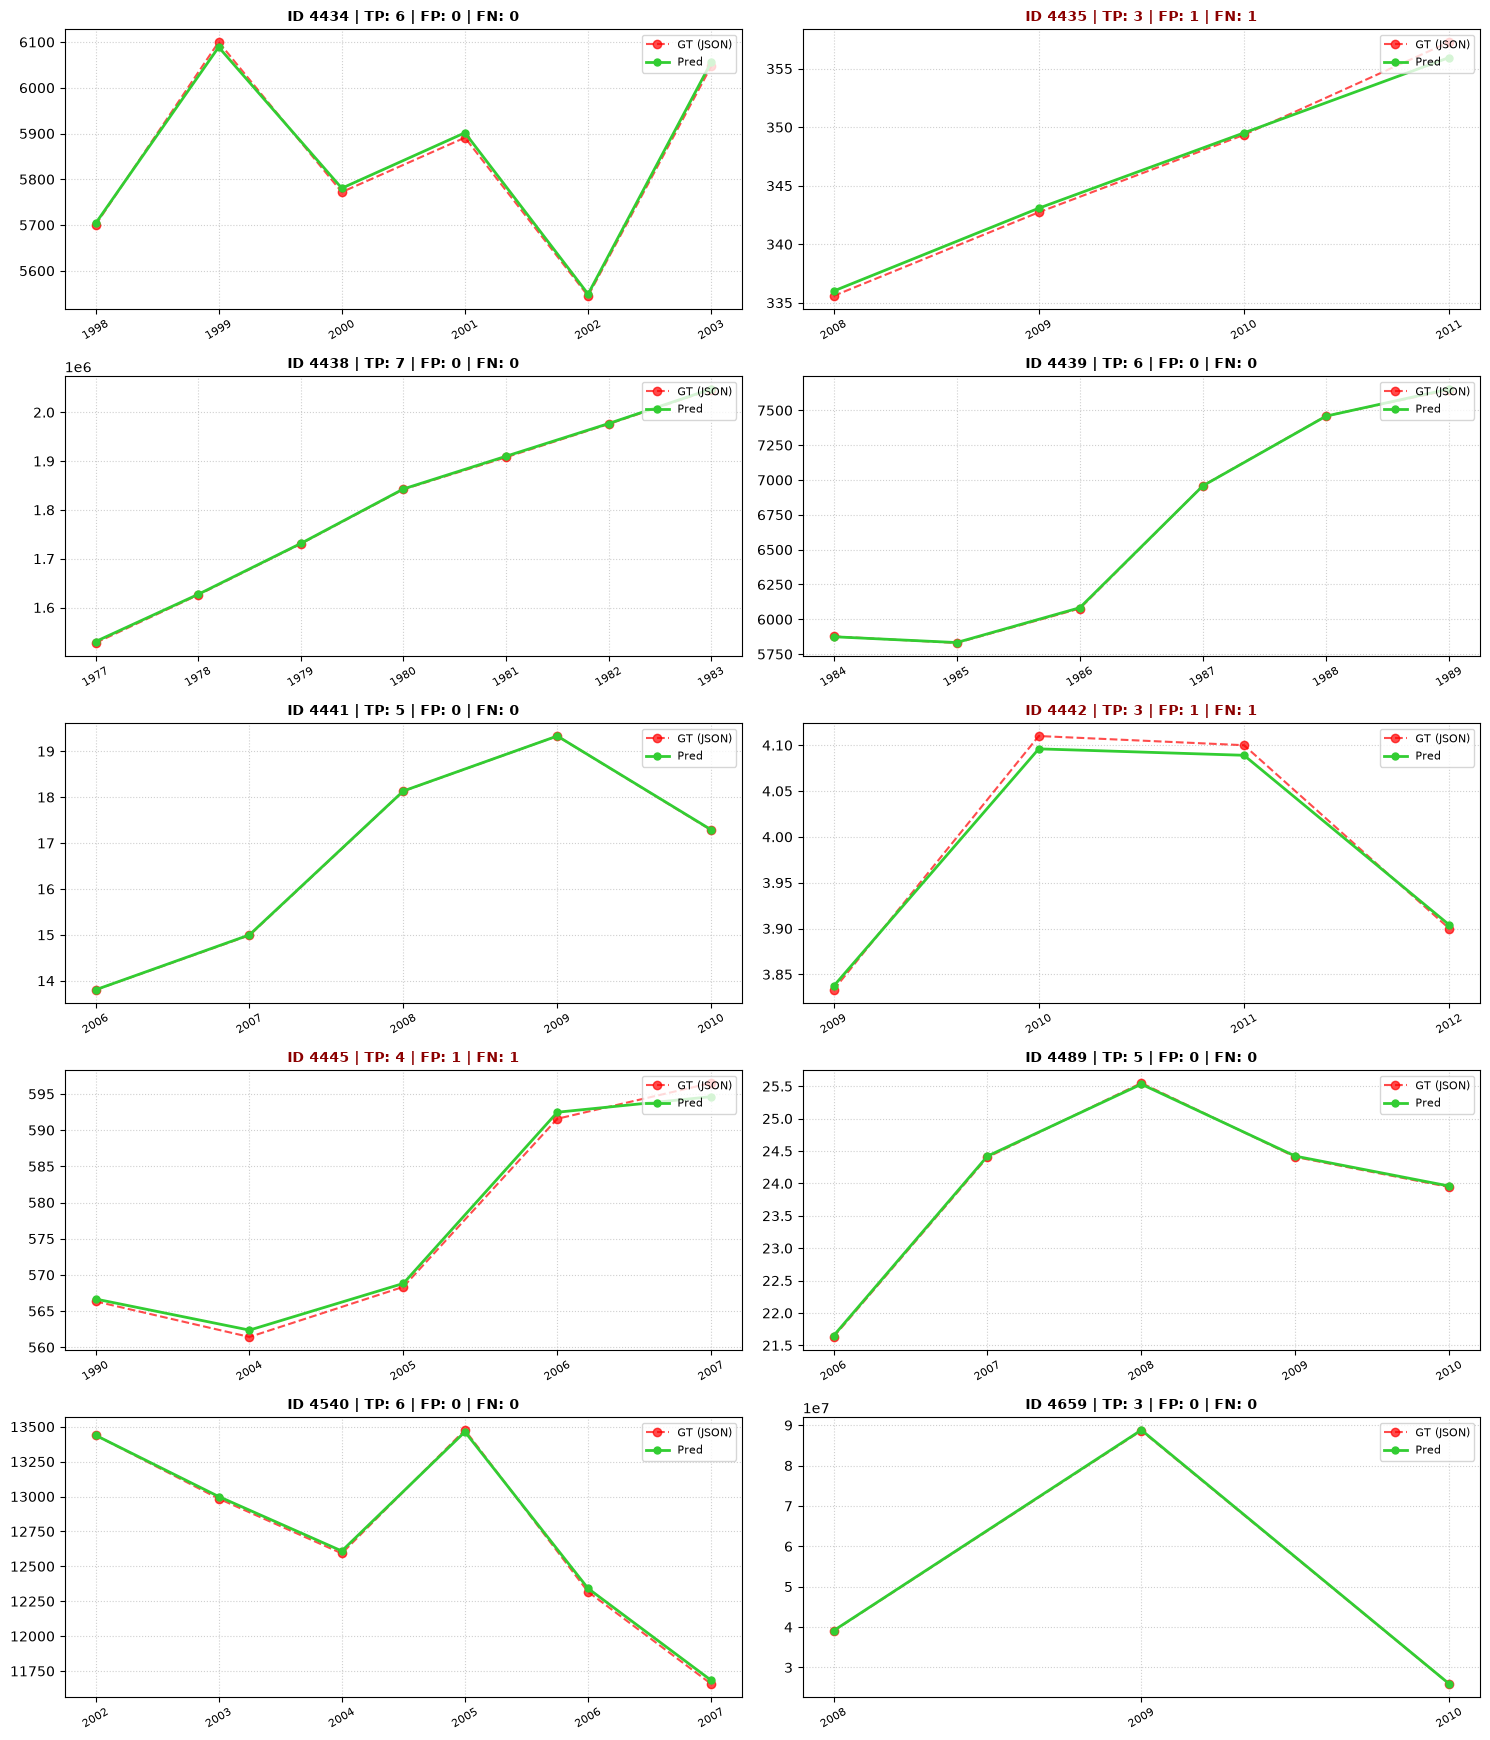

In [155]:
cols = 2
rows = math.ceil(len(dev_ids) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, 3.5 * rows))

if len(dev_ids) == 1:
    axes = [axes]
else:
    axes = axes.flatten()


def sort_key(pt):
    x = pt["x"]
    try:
        return float(x)
    except ValueError:
        return str(x)


for idx, dev_id in enumerate(dev_ids):
    ax = axes[idx]

    preds = dev_mapped_actual_values_2.get(dev_id, [])
    gts = dev_gt_actual_values_2.get(dev_id, [])

    preds_sorted = sorted(preds, key=sort_key)
    gts_sorted = sorted(gts, key=sort_key)

    pred_x = [str(pt["x"]) for pt in preds_sorted]
    pred_y = [pt["y"] for pt in preds_sorted]

    gt_x = [str(pt["x"]) for pt in gts_sorted]
    gt_y = [pt["y"] for pt in gts_sorted]

    ax.plot(
        gt_x,
        gt_y,
        "o--",
        color="red",
        label="GT (JSON)",
        markersize=6,
        linewidth=1.5,
        alpha=0.7,
    )

    ax.plot(
        pred_x,
        pred_y,
        "o-",
        color="limegreen",
        label="Pred",
        markersize=5,
        linewidth=2,
    )

    res = results_tp_fp_fn_2.get(dev_id, {"TP": 0, "FP": 0, "FN": 0})

    has_error = res["FN"] > 0 or res["FP"] > 0
    title_color = "darkred" if has_error else "black"

    ax.set_title(
        f"ID {dev_id} | TP: {res['TP']} | FP: {res['FP']} | FN: {res['FN']}",
        fontsize=10,
        fontweight="bold",
        color=title_color,
    )
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=8, loc="upper right")
    ax.tick_params(axis="x", rotation=30, labelsize=8)

for j in range(len(dev_ids), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

wyniki wygladaja bardzo dobrze, zostaly drobne błędy, które nie wpływają juz bardzo na nasze wyniki końcowe
algorytm sobie radzi z wykrywaniem punktow oraz z ich przeliczaniem, dlatego na tym zostajemy

### OSTATECZNA ARCHITEKTURA CONVERTER.PY ###

Moduł odpowiada za transformację wykrytych na obrazie punktów pikselowych (cx, cy) na rzeczywiste wartości liczbowe oraz kategoryczne osi (X, Y) wykresu wykorzystująć metadane układu współrzędnych wykresu (general_figure_info)

#### Opis działania algorytmu:

Przetwarzanie punktów pikselowych na wartości osi odbywa się w trzech etapach:

1. **Wyznaczenie ciągłego odwzorowania osi Y (regresja liniowa):**
    * Na podstawie podziałek osi Y (y_axis -> major_ticks) obliczane są środki pionowe ich ramek ograniczających (Ypix = Y + H/2)
    * dla sparowanych współrzędnych pikselowych i wartości liczbowych ropasowywany jest model regresji liniowej stopnia pierwszego przy uzyciu np.polyfit
    * model liniowy gwarantuje dokładną ekstapolację dla punktów wykraczających poza skrajne znaczniki podziałki osi Y (rozwiązuje problem spłaszczania linii przy krawędziach wykresu)

2. **precyzyjne pozycjonowanie osi X z podziałek (major_ticks)**
    * pozycje poziome podziałek osi pobierane są bezpośrednio z (x_axis -> major_ticks -> bboxes)
    * kazdej pozycji x przypisywana jest odpowiadająca jej etykieta tekstowa z (x_axis -> major_labels -> values)

3. **transformacja punktów (nearest-neighbor):**
    * Dla kazdego punkty wejsciowego (cx, cy):
        * wartosc Y jest wyliczana z prostej regresji za pomoca np.polyval(poly_y, cy)
        * wartość X jest przypisywana poprzez odnalezienie najblizszej podzialki osi X na podstawie minimalnej odleglosci bezwzględnej

4. **Ekstrakcja punktów kalibracyjnych:**
    * funkcja extract_calibration_points pobiera geometrie samej prostej osi (y_axis -> rule) oraz (x_axis -> rule) i łączy ją ze środkami podziałek, wyznaczając pełne punkty 2D osi w pikselach.
    
#### specyfikacja interfejsu:

* wejście: pixels_list (lista slownikow zawierajacych wspolrzedne pikselowe punktow)

* fig_info: slownik metadanych wykresu z sekcji 'general_figure_info':
    * y_axis -> rule & x_axis -> rule: ramki osi glownej (bbox)
    * y_axis -> major_ticks: ramki podziałek (bboxes) oraz ich wartosci liczbowe (values)
    * x_axis -> major_ticks: ramki podziałek (bboxes)
    * x_axis -> major_labels: wartosci etykiet czasowych (values)

* wyjście: lista slownikow z przeliczonymi wartosciami docelowymi